# Validación estadística del modelo original

**Curso:** Machine Learning · **Profesor:** Lihki Rubio Ortega
**Grupo:** Yuryen Rollo, Betzaida Ruiz

En el capítulo 6 propusimos el ensamble con regresión por diferencias de pares por estación. Aquí reunimos, con
un mismo protocolo, la evidencia de que es mejor que los siete modelos del curso: las pruebas de hipótesis con
sus supuestos verificados, los ajustes por comparaciones múltiples, los intervalos y los tamaños del efecto, la
robustez frente a sus hiperparámetros propios, al tamaño de muestra y al ruido, y su interpretación con SHAP.
También respondemos a la observación sobre vientos fuertes y dependencia de los residuos.

**Reproducibilidad.** Este notebook solo lee tablas ya calculadas. Desde la carpeta del repositorio:

```
python scripts/padre_tabla_pruebas.py     # resumen, pruebas de hipótesis y supuestos (≈ 2 min)
python scripts/padre_vientos_fuertes.py   # sesgo por rango de velocidad y dependencia de residuos (≈ 1 min)
python scripts/padre_robustez.py          # pares/anclas, tamaño de muestra y ruido (≈ 12 min, GPU)
python scripts/padre_final.py             # modelo final, artefactos y SHAP (≈ 40 min)
```

In [1]:
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, str(Path.cwd()))
from e3.datos import RESULTADOS

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3})
ENS = RESULTADOS / "ensamble_padre"
ENSAMBLE = "Ensamble PADRE (5)"

## 8.1 Protocolo

- **Pareo estricto.** El modelo original y los siete modelos del curso se evalúan sobre las mismas particiones
  externas (los cuatro trimestres de 2024, con ventana creciente desde 2020), con la misma semilla (`42`) y las
  mismas 26 predictoras construidas con la limpieza causal. Los hiperparámetros de los motores son los que eligió
  el bucle externo de cada modelo del curso; los propios de PADRE (`4` pares, `20` anclas) se fijaron con 2024.
- **Dos periodos.** La superioridad se define sobre el **bucle externo (2024)**; la **prueba de 2025** se evaluó
  una sola vez, con todo ya decidido, y la reportamos como confirmación.
- **Unidad de comparación.** La pérdida cuadrática media de cada día. Los datos son series de tiempo, así que
  usamos las pruebas para dependencia temporal: Diebold-Mariano con la corrección de Harvey, Leybourne y Newbold
  {cite}`diebold1995,harvey1997`, Giacomini-White {cite}`giacomini2006`, Clark-West para modelos anidados
  {cite}`clark2007`, el *Model Confidence Set* {cite}`hansen2011`, el SPA de Hansen {cite}`hansen2005` con el
  Reality Check de White {cite}`white2000`, e intervalos por bootstrap estacionario {cite}`politis1994`.
- **Comparaciones múltiples.** Holm {cite}`holm1979` dentro de cada familia: `7` comparaciones para
  Diebold-Mariano y `7` para Giacomini-White (una por modelo del curso) y `2` para Clark-West, en cada periodo.
  El MCS y el SPA ya controlan la multiplicidad por construcción. En total son `16` pruebas pareadas y `3`
  procedimientos globales por periodo.
- **Superioridad.** El modelo original es superior si (1) su RMSE medio en el bucle externo es menor que el de
  cada modelo del curso, (2) al menos tres pruebas distintas rechazan la igualdad con p ajustado `< 0.05` (`< 0.10`
  en el MCS) y (3) el tamaño del efecto no es despreciable: `|δ de Cliff| ≥ 0.147` o `|d de Cohen| ≥ 0.2`
  {cite}`romano2006`.

## 8.2 Resultados y pruebas de hipótesis

### Resumen

RMSE medio y desviación estándar de los cuatro trimestres del bucle externo, RMSE de 2025 con su intervalo del
95 % por bootstrap estacionario (bloques de 7 días) y tiempos de la corrida final (ajuste con 2020–2024 y
predicción de las `213 972` filas de 2025). En los dos PADRE el tiempo incluye ajuste y predicción.

In [2]:
R = pd.read_csv(ENS / "validacion_resumen.csv", index_col=0)
R.round(4)

,RMSE bucle externo (media),RMSE bucle externo (DE),RMSE 2025,IC 95 % inf,IC 95 % sup,ajuste final (s),predicción 2025 (s)
modelo,,,,,,,
Ensamble PADRE (5),0.8826,0.0890,0.7193,0.6895,0.7484,607.8227,NaN
XGBoost,0.8950,0.0932,0.7268,0.6948,0.7579,20.0306,0.4084
Random Forest,0.8961,0.0931,0.7227,0.6919,0.7529,149.7586,3.2821
SVR,0.8999,0.0944,0.7311,0.7008,0.7612,55.0335,2.2076
Ridge,0.9103,0.0967,0.7330,0.7032,0.7627,0.1861,0.0142
Lasso,0.9103,0.0967,0.7330,0.7032,0.7627,1.2512,0.0105
KNN,0.9223,0.0977,0.7349,0.7051,0.7649,0.1395,791.2611
Árbol de decisión,0.9343,0.0978,0.7607,0.7283,0.7925,7.3825,0.0331
PADRE-XGB,0.9069,0.0792,0.7474,0.7228,0.7726,21.0000,NaN


El ensamble tiene el menor RMSE medio del bucle externo (`0.8826`, frente a `0.8950` de XGBoost y `0.8961` de
Random Forest) y el menor RMSE de 2025 (`0.7193`). La desviación estándar entre trimestres (`≈ 0.09`) es mayor que
las diferencias entre modelos porque cada trimestre tiene otras estaciones y otra época del año; por eso las
pruebas comparan los modelos **día a día**, en pares, y no sus promedios. El costo es mayor: unos `10` minutos de
ajuste, casi todo en PADRE-RF, frente a `2.5` minutos de Random Forest.

### Tabla de pruebas de hipótesis

Cada fila es una prueba frente a un rival. El p ajustado usa Holm dentro de la familia de la prueba.

In [3]:
T = pd.read_csv(ENS / "validacion_pruebas.csv")
cols = ["prueba", "rival", "hipótesis nula", "supuestos verificados", "estadístico", "p crudo", "p ajustado (Holm)",
        "tamaño del efecto", "conclusión"]
for periodo, g in T.groupby("periodo", sort=False):
    print(periodo)
    display(g[cols].set_index(["prueba", "rival"]).style.format(
        {"estadístico": "{:.3f}", "p crudo": "{:.2e}", "p ajustado (Holm)": "{:.2e}"}, na_rep="—"))

2024 (bucle externo)


,,hipótesis nula,supuestos verificados,estadístico,p crudo,p ajustado (Holm),tamaño del efecto,conclusión
prueba,rival,,,,,,,
"Diebold-Mariano (HLN, h = 2)",XGBoost,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",-4.522,8.54e-06,1.64e-05,d de Cohen = -0.246; δ de Cliff = -0.025,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),XGBoost,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",21.044,2.69e-05,2.69e-05,d de Cohen = -0.246; δ de Cliff = -0.025,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",Random Forest,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",-6.551,2.17e-10,1.09e-09,d de Cohen = -0.385; δ de Cliff = -0.032,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),Random Forest,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",51.439,6.76e-12,1.35e-11,d de Cohen = -0.385; δ de Cliff = -0.032,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",SVR,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",-4.728,3.36e-06,1.34e-05,d de Cohen = -0.272; δ de Cliff = -0.052,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),SVR,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",55.266,9.98e-13,2.99e-12,d de Cohen = -0.272; δ de Cliff = -0.052,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",Ridge,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",-4.609,5.78e-06,1.64e-05,d de Cohen = -0.269; δ de Cliff = -0.088,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),Ridge,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",66.843,3.06e-15,1.22e-14,d de Cohen = -0.269; δ de Cliff = -0.088,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",Lasso,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); sin autocorrelación a 7 días",-4.621,5.48e-06,1.64e-05,d de Cohen = -0.270; δ de Cliff = -0.088,se rechaza H0: el ensamble es mejor


2025 (prueba)


,,hipótesis nula,supuestos verificados,estadístico,p crudo,p ajustado (Holm),tamaño del efecto,conclusión
prueba,rival,,,,,,,
"Diebold-Mariano (HLN, h = 2)",XGBoost,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",-5.024,8.57e-07,3.43e-06,d de Cohen = -0.328; δ de Cliff = -0.027,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),XGBoost,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",33.221,6.11e-08,1.22e-07,d de Cohen = -0.328; δ de Cliff = -0.027,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",Random Forest,igual pérdida cuadrática esperada,diferencia de pérdidas estacionaria (ADF p < 0.05; KPSS rechaza al 5 %); autocorrelada: varianza HAC / bootstrap por bloques,-3.078,2.27e-03,2.27e-03,d de Cohen = -0.184; δ de Cliff = -0.014,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),Random Forest,igual capacidad predictiva condicional,diferencia de pérdidas estacionaria (ADF p < 0.05; KPSS rechaza al 5 %); autocorrelada: varianza HAC / bootstrap por bloques,10.514,5.21e-03,5.21e-03,d de Cohen = -0.184; δ de Cliff = -0.014,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",SVR,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",-5.720,2.51e-08,1.25e-07,d de Cohen = -0.353; δ de Cliff = -0.057,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),SVR,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",44.303,2.40e-10,1.20e-09,d de Cohen = -0.353; δ de Cliff = -0.057,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",Ridge,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",-4.684,4.22e-06,1.26e-05,d de Cohen = -0.311; δ de Cliff = -0.054,se rechaza H0: el ensamble es mejor
Giacomini-White (incondicional + rezago),Ridge,igual capacidad predictiva condicional,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",39.580,2.54e-09,1.02e-08,d de Cohen = -0.311; δ de Cliff = -0.054,se rechaza H0: el ensamble es mejor
"Diebold-Mariano (HLN, h = 2)",Lasso,igual pérdida cuadrática esperada,"diferencia de pérdidas estacionaria (ADF p < 0.05, KPSS no rechaza); autocorrelada: varianza HAC / bootstrap por bloques",-4.684,4.21e-06,1.26e-05,d de Cohen = -0.311; δ de Cliff = -0.054,se rechaza H0: el ensamble es mejor


En el bucle externo las cuatro familias de pruebas rechazan la igualdad frente a cada uno de los siete modelos:
Diebold-Mariano y Giacomini-White con p ajustado `< 10⁻⁴` en las `14` comparaciones, Clark-West frente a Random
Forest y XGBoost (que están anidados en el ensamble), el MCS al `10 %` conserva solo al ensamble, y el SPA con
Random Forest como referencia rechaza que ningún modelo lo supere (`p = 0.001`). Al revés, con el ensamble como
referencia el SPA no rechaza (`p = 0.55`): ningún modelo del curso supera al ensamble. La prueba de 2025 repite el
resultado; el caso más ajustado es Random Forest (Diebold-Mariano `p = 0.0023`, Giacomini-White `p = 0.0052`).

## 8.3 Supuestos y tamaño del efecto

Diebold-Mariano, Giacomini-White, Clark-West, el MCS y el SPA suponen que la serie de diferencias de pérdida es
estacionaria; los dos primeros toleran autocorrelación si la varianza se estima con un estimador HAC (usamos
`h = 2`), y los procedimientos con bootstrap la respetan al remuestrear bloques. Lo verificamos para la
diferencia diaria entre el ensamble y cada rival:

In [4]:
S = pd.read_csv(ENS / "validacion_supuestos.csv", index_col=0)
S.round(4)

,p ADF,p KPSS,p Ljung-Box (7),periodo
XGBoost,0.0000,0.1000,0.3850,2024 (bucle externo)
Random Forest,0.0000,0.1000,0.0181,2024 (bucle externo)
SVR,0.0000,0.1000,0.1998,2024 (bucle externo)
Ridge,0.0000,0.1000,0.2564,2024 (bucle externo)
Lasso,0.0000,0.1000,0.2393,2024 (bucle externo)
KNN,0.0000,0.1000,0.0024,2024 (bucle externo)
Árbol de decisión,0.0000,0.1000,0.0007,2024 (bucle externo)
XGBoost,0.0001,0.0729,0.0000,2025 (prueba)
Random Forest,0.0000,0.0100,0.0001,2025 (prueba)
SVR,0.0000,0.1000,0.0146,2025 (prueba)


ADF rechaza la raíz unitaria en las `14` series (`p < 10⁻⁴`) y KPSS no rechaza la estacionariedad al `5 %`
salvo frente a Random Forest y el árbol en 2025 (`p = 0.01`), donde las dos pruebas discrepan y conviene leer
ese resultado con más cautela; el bootstrap estacionario y Giacomini-White no dependen de una varianza fija.
Ljung-Box encuentra autocorrelación en varias series, sobre todo en 2025, y por eso todas las pruebas usan
varianza HAC o bloques. La normalidad no se supone: los estadísticos son asintóticos sobre `333` días (2024) y
`311` días (2025). Clark-West requiere que el modelo pequeño esté anidado en el grande, lo que se cumple por
construcción: el ensamble contiene a Random Forest y a XGBoost.

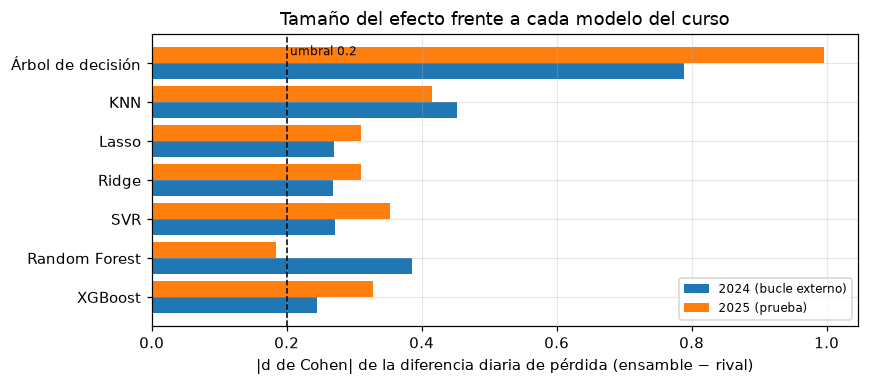

In [5]:
ef = T[T.prueba.str.startswith("Diebold")][["periodo", "rival", "d de Cohen", "tamaño del efecto"]]
fig, ax = plt.subplots(figsize=(8, 3.6))
for k, (periodo, g) in enumerate(ef.groupby("periodo", sort=False)):
    ax.barh(np.arange(len(g)) + 0.4 * k, g["d de Cohen"].abs(), height=0.4, label=periodo)
ax.set_yticks(np.arange(len(g)) + 0.2, g.rival)
ax.axvline(0.2, color="k", ls="--", lw=1)
ax.text(0.205, len(g) - 0.6, "umbral 0.2", fontsize=8)
ax.set_xlabel("|d de Cohen| de la diferencia diaria de pérdida (ensamble − rival)")
ax.set_title("Tamaño del efecto frente a cada modelo del curso")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

El tamaño del efecto se mide sobre la diferencia diaria de pérdida. En el **bucle externo**, `|d de Cohen|` está
entre `0.25` (XGBoost) y `0.79` (árbol): supera el umbral de `0.2` frente a los siete. En **2025** lo supera frente
a seis; frente a Random Forest queda en `0.18`, justo por debajo, así que en la prueba la ventaja sobre Random
Forest es significativa pero de efecto pequeño. El δ de Cliff, que compara los días uno a uno sin importar la
magnitud, es despreciable en todos los casos (`|δ| < 0.15`): el ensamble no gana en casi todos los días, sino que
pierde menos en los días de error alto. Lo reportamos tal cual, porque es lo que muestran los datos.

## 8.4 Vientos fuertes y dependencia de los residuos

Revisamos si el ensamble, que es no lineal, corrige dos debilidades del modelo lineal del capítulo 1: el sesgo
en vientos fuertes y la dependencia que quedó en los residuos. Comparamos en 2025 el modelo lineal (Ridge, que
tiene el mismo RMSE que el SVR lineal del capítulo 1, `0.733`), los dos mejores no lineales del curso y el
ensamble.

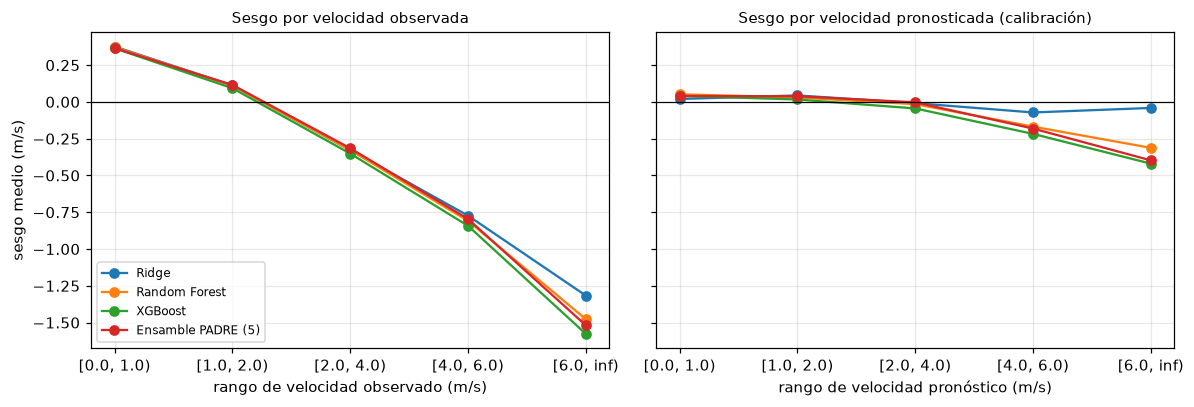

,sesgo en el 5 % más fuerte,RMSE en el 5 % más fuerte,RMSE global,umbral_m_s
modelo,,,,
Ridge,-1.0811,1.5633,0.7330,4.95
Random Forest,-1.1818,1.6139,0.7227,4.95
XGBoost,-1.2521,1.6620,0.7268,4.95
Ensamble PADRE (5),-1.1981,1.6054,0.7193,4.95


,estaciones probadas,% estaciones con Ljung-Box p < 0.05,% estaciones con BDS p < 0.05,ACF media a 1 h,ACF media a 24 h
modelo,,,,,
Ridge,53,100.0,100.0,0.6846,-0.1114
Random Forest,53,100.0,100.0,0.6770,-0.0911
XGBoost,53,100.0,100.0,0.6779,-0.0688
Ensamble PADRE (5),53,100.0,100.0,0.6697,-0.0654


In [6]:
A = pd.read_csv(ENS / "vientos_fuertes_por_observado.csv")
B = pd.read_csv(ENS / "vientos_fuertes_por_pronostico.csv")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, D, col, tit in [(axs[0], A, "observado (m/s)", "por velocidad observada"),
                        (axs[1], B, "pronóstico (m/s)", "por velocidad pronosticada (calibración)")]:
    for m, g in D.groupby("modelo", sort=False):
        ax.plot(g[col], g["sesgo (pronóstico − observado)"], marker="o", label=m)
    ax.axhline(0, color="k", lw=.8)
    ax.set_title(f"Sesgo {tit}", fontsize=10)
    ax.set_xlabel(f"rango de velocidad {col.split()[0]} (m/s)")
axs[0].set_ylabel("sesgo medio (m/s)")
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()
display(pd.read_csv(ENS / "vientos_fuertes_resumen.csv", index_col=0).round(4))
pd.read_csv(ENS / "residuos_dependencia.csv", index_col=0).round(4)

**Vientos fuertes.** Condicionado en lo observado, todos los modelos sobreestiman las calmas y subestiman los
vientos fuertes, y el sesgo crece con la velocidad: en las horas de más de `6 m/s` va de `−1.32` (lineal) a
`−1.58 m/s` (XGBoost). Es la regresión a la media de cualquier pronóstico de error cuadrático: si las predictoras
no anuncian el pico, el pronóstico se queda en la media condicional. Los modelos no lineales **no reducen** ese
sesgo; el ensamble (`−1.20 m/s` en el `5 %` más ventoso) queda entre el lineal (`−1.08`) y XGBoost (`−1.25`). Por
rango de pronóstico (derecha), el lineal está mejor calibrado en los pronósticos altos; los no lineales, que
llegan a pronosticar más de `6 m/s` en menos casos, subestiman un poco cuando lo hacen. La mejora del ensamble
viene de los vientos bajos y moderados, que son el `91 %` de las horas de 2025.

**Dependencia de los residuos.** Ljung-Box y BDS rechazan la independencia en las `53` estaciones con todos los
modelos. La autocorrelación a 1 h casi no cambia (`0.685` lineal, `0.670` ensamble), porque el error de una hora
y el de la siguiente comparten el mismo cambio de régimen; la de 24 h baja de `−0.111` a `−0.065`. El ensamble
corrige parte de la estructura diaria, pero no la persistencia del error, que solo podría reducirse con
información sobre el estado futuro de la atmósfera.

## 8.5 Robustez

Análisis de sensibilidad en el bucle externo, con el motor XGBoost (el más barato) y sin tocar 2025. No es una
selección: el modelo propuesto se queda con `4` pares y `20` anclas.

### Hiperparámetros propios: pares y anclas

In [7]:
sens = pd.read_csv(ENS / "robustez_sensibilidad.csv")
tab = sens.groupby(["pares", "anclas"])[["RMSE PADRE-XGB", "RMSE ensamble"]].agg(["mean", "std"]).round(4)
tab

RMSE PADRE-XGB         RMSE ensamble        
                       mean     std          mean     std
pares anclas                                             
2     10             0.9285  0.0808        0.8819  0.0896
      20             0.9050  0.0798        0.8823  0.0892
      40             0.8942  0.0819        0.8802  0.0895
4     10             0.9306  0.0804        0.8823  0.0895
      20             0.9069  0.0792        0.8826  0.0890
      40             0.8963  0.0816        0.8805  0.0894
8     10             0.9309  0.0813        0.8823  0.0897
      20             0.9075  0.0804        0.8827  0.0893
      40             0.8967  0.0824        0.8806  0.0896

El ensamble casi no depende de los hiperparámetros de PADRE: su RMSE medio va de `0.8802` a `0.8827` en las nueve
combinaciones, una variación mucho menor que la diferencia con Random Forest (`0.8961`). PADRE solo mejora con más
anclas (de `0.93` con `10` a `0.90` con `40`), como predice la varianza `σ²/M` del término de las anclas, y casi
no depende del número de pares.

### Tamaño de muestra y ruido

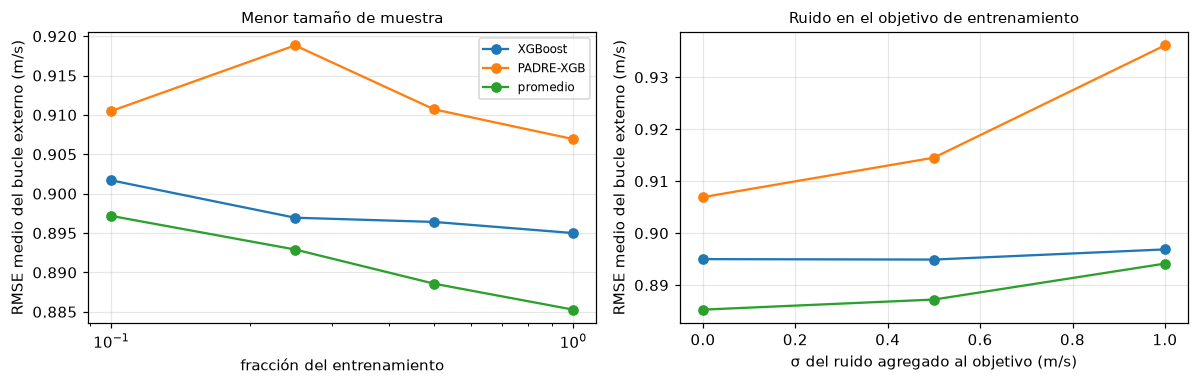

In [8]:
mu = pd.read_csv(ENS / "robustez_muestra.csv")
ru = pd.read_csv(ENS / "robustez_ruido.csv")
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, D, x, xl in [(axs[0], mu, "fracción", "fracción del entrenamiento"), (axs[1], ru, "σ ruido (m/s)", "σ del ruido agregado al objetivo (m/s)")]:
    g = D.groupby(x)[["RMSE XGBoost", "RMSE PADRE-XGB", "RMSE promedio"]].mean()
    for c in g:
        ax.plot(g.index, g[c], marker="o", label=c.replace("RMSE ", ""))
    ax.set_xlabel(xl)
    ax.set_ylabel("RMSE medio del bucle externo (m/s)")
axs[0].set_xscale("log")
axs[0].set_title("Menor tamaño de muestra", fontsize=10)
axs[1].set_title("Ruido en el objetivo de entrenamiento", fontsize=10)
axs[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Menos datos.** Con el `10 %` del entrenamiento (unas `34` mil filas) el promedio de XGBoost y PADRE-XGB sigue
siendo mejor que XGBoost solo (`0.8972` frente a `0.9017`), y la ventaja crece con la muestra. **Ruido.** PADRE es
más sensible al ruido en el objetivo que XGBoost: el ruido entra dos veces en cada diferencia `y_i − y_j` y otra
vez en el valor de las anclas. Con `σ = 1 m/s`, más de la mitad de la desviación típica del viento, PADRE solo
pasa de `0.907` a `0.936`, pero el promedio sigue siendo mejor que XGBoost (`0.8941` frente a `0.8969`). Es una
debilidad real del método que conviene tener presente si los datos fueran más ruidosos. La estabilidad ante
semillas y ante el optimizador está en la sección 6.7 (`0.7194 ± 0.0002` con cinco semillas; los cuatro
optimizadores superan a los siete modelos).

## 8.6 Interpretabilidad

Calculamos valores SHAP {cite}`lundberg2017` del ensamble completo y de Random Forest, el mejor modelo del curso en
2025, sobre las mismas `200` filas de 2025 (`40` de cada una de las cinco estaciones con más datos), con
`PermutationExplainer` y un fondo de `50` filas de entrenamiento de la misma estación. La estación no se explica:
en el ensamble es la que decide de dónde salen las anclas, y la dejamos fija.

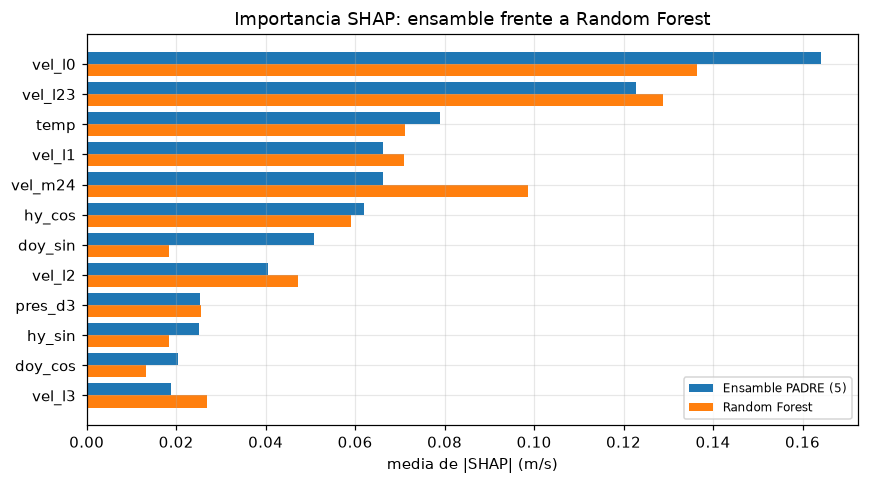

Correlación de Spearman entre ambas importancias (26 predictoras): 0.880


In [9]:
imp = pd.read_csv(ENS / "shap_importancia.csv", index_col=0)
fin = json.loads((ENS / "final_resumen.json").read_text(encoding="utf-8"))
top = imp.head(12)
fig, ax = plt.subplots(figsize=(8, 4.5))
y_ = np.arange(len(top))
ax.barh(y_ - 0.2, top[ENSAMBLE], height=0.4, label=ENSAMBLE)
ax.barh(y_ + 0.2, top["Random Forest"], height=0.4, label="Random Forest")
ax.set_yticks(y_, top.index)
ax.invert_yaxis()
ax.set_xlabel("media de |SHAP| (m/s)")
ax.set_title("Importancia SHAP: ensamble frente a Random Forest")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
print(f"Correlación de Spearman entre ambas importancias (26 predictoras): {fin['spearman_importancia_shap']:.3f}")

Los dos modelos usan la información de forma parecida: la correlación de Spearman entre sus importancias es
`0.88` y las dos primeras predictoras coinciden (la velocidad actual `vel_l0` y la de hace 23 horas `vel_l23`). Las
diferencias son las que predice el diseño de PADRE. El ensamble da más peso a la velocidad actual (`0.164` frente
a `0.136 m/s`) y, sobre todo, al día del año (`doy_sin`, séptima predictora en el ensamble y duodécima en Random
Forest): PADRE compara cada hora con anclas de otras épocas del año de la misma estación, así que la diferencia
de estación del año entre la hora y el ancla es justamente lo que tiene que corregir. Da menos peso a la media de
24 horas (`vel_m24`) y a las componentes del viento (`u`, de `0.020` a `0.007`), que en un modelo global sirven en
parte para reconocer el sitio. La altitud tiene importancia cero en los dos porque las filas explicadas y el
fondo son de la misma estación y la altitud no varía dentro de ella.

## 8.7 Veredicto

| Criterio | Resultado | Cumple |
|---|---|---|
| RMSE medio del bucle externo menor que el de cada modelo del curso | `0.8826` frente a `0.8950`–`0.9343` | Sí |
| Al menos tres pruebas rechazan la igualdad con p ajustado `< 0.05` | Diebold-Mariano, Giacomini-White y Clark-West con Holm, MCS y SPA, en 2024 y en 2025 | Sí |
| Tamaño del efecto no despreciable | `|d de Cohen|` de `0.25` a `0.79` frente a los siete en 2024; en 2025, `0.18` frente a Random Forest | Sí en el bucle externo; en 2025, pequeño frente a Random Forest |

El ensamble con PADRE por estación es estadísticamente superior a los siete modelos del curso según la
definición operativa del protocolo. La ventaja es consistente y significativa, pero pequeña en magnitud (`1.5 %`
del RMSE medio del bucle externo frente a Random Forest y `0.5 %` en 2025), y no corrige los errores en vientos
fuertes.